<a href="https://colab.research.google.com/github/shahaanabbas-13/Quantum-Diabetes-Prediction/blob/main/notebooks/07_Experimental_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 07 — Experimental analysis, threshold tuning and ablation
This notebook collects exported result CSVs, calculates a recall-oriented threshold on validation predictions, and produces comparison plots. Never choose the threshold using the final test labels.

**Cell 1 – Import libraries and load all experiment results**

In [6]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import warnings

warnings.filterwarnings("ignore")

# Results directory
RESULTS = Path("/content/results")
RESULTS.mkdir(parents=True, exist_ok=True)

# Required result files
required_files = [
    "classical_cv.csv",
    "feature_selection_cv.csv",
    "qsvm_results.csv",
    "vqc_results.csv"
]

# Check whether all result files are available
missing_files = [
    file for file in required_files
    if not (RESULTS / file).exists()
]

if missing_files:
    raise FileNotFoundError(
        f"Missing result files: {missing_files}\n"
        "Upload or download these files into /content/results/ before proceeding."
    )

# Load experiment results
classical_results = pd.read_csv(RESULTS / "classical_cv.csv")
feature_results = pd.read_csv(RESULTS / "feature_selection_cv.csv")
qsvm_results = pd.read_csv(RESULTS / "qsvm_results.csv")
vqc_results = pd.read_csv(RESULTS / "vqc_results.csv")

# Display dataset dimensions and columns
result_tables = {
    "Classical ML CV": classical_results,
    "Feature Selection CV": feature_results,
    "QSVM Test Results": qsvm_results,
    "VQC Test Results": vqc_results
}

for name, df in result_tables.items():
    print(f"\n{'=' * 60}")
    print(name)
    print(f"Shape: {df.shape}")
    print("Columns:", df.columns.tolist())
    display(df)

print("\nAll four experiment result files loaded successfully.")


Classical ML CV
Shape: (4, 9)
Columns: ['representation', 'accuracy_mean', 'recall_mean', 'f1_mean', 'roc_auc_mean', 'accuracy_std', 'recall_std', 'f1_std', 'roc_auc_std']


,representation,accuracy_mean,recall_mean,f1_mean,roc_auc_mean,accuracy_std,recall_std,f1_std,roc_auc_std
0,All 8 features,0.762202,0.700997,0.672385,0.844381,0.011053,0.039478,0.013319,0.016074
1,Mutual Information (4),0.755684,0.710188,0.669672,0.833915,0.012886,0.019865,0.012305,0.019703
2,RFE (4),0.771985,0.729125,0.690115,0.842306,0.013625,0.042225,0.014537,0.018942
3,PCA (4),0.732907,0.687154,0.640040,0.826476,0.024237,0.080559,0.046569,0.009926



Feature Selection CV
Shape: (4, 5)
Columns: ['representation', 'accuracy', 'recall', 'f1', 'roc_auc']


,representation,accuracy,recall,f1,roc_auc
0,All 8 features,0.747313,0.727393,0.668809,0.836225
1,Mutual Information (4),0.736864,0.697554,0.650804,0.829448
2,RFE (4),0.764222,0.723899,0.684152,0.840164
3,PCA (4),0.730396,0.708805,0.648018,0.810744



QSVM Test Results
Shape: (1, 25)
Columns: ['model', 'accuracy', 'precision', 'recall', 'f1_score', 'f2_score', 'roc_auc', 'pr_auc', 'specificity', 'true_negative', 'false_positive', 'false_negative', 'true_positive', 'total_samples', 'training_samples', 'quantum_training_samples', 'test_samples', 'number_of_qubits', 'number_of_features', 'selected_features', 'imputation', 'feature_selection', 'kernel', 'execution_time_seconds', 'random_state']


,model,accuracy,precision,recall,f1_score,f2_score,roc_auc,pr_auc,specificity,true_negative,...,quantum_training_samples,test_samples,number_of_qubits,number_of_features,selected_features,imputation,feature_selection,kernel,execution_time_seconds,random_state
0,QSVM,0.720779,0.57971,0.740741,0.650407,0.701754,0.797593,0.660188,0.71,71,...,250,154,4,4,"Glucose, Insulin, BMI, Age",KNN,Mutual Information,Fidelity Quantum Kernel,498.38,42



VQC Test Results
Shape: (1, 30)
Columns: ['model', 'accuracy', 'precision', 'recall', 'f1_score', 'f2_score', 'roc_auc', 'pr_auc', 'specificity', 'true_negative', 'false_positive', 'false_negative', 'true_positive', 'total_samples', 'training_samples', 'quantum_training_samples', 'test_samples', 'number_of_qubits', 'number_of_features', 'selected_features', 'imputation', 'feature_selection', 'circuit', 'number_of_layers', 'epochs', 'learning_rate', 'optimizer', 'decision_threshold', 'execution_time_seconds', 'random_state']


,model,accuracy,precision,recall,f1_score,f2_score,roc_auc,pr_auc,specificity,true_negative,...,imputation,feature_selection,circuit,number_of_layers,epochs,learning_rate,optimizer,decision_threshold,execution_time_seconds,random_state
0,VQC,0.623377,0.452381,0.351852,0.395833,0.368217,0.654444,0.456586,0.77,77,...,KNN,Mutual Information,AngleEmbedding + StronglyEntanglingLayers,2,30,0.03,Adam,0.5,165.77,42



All four experiment result files loaded successfully.


**Cell 2 – Compare classical ML and feature-selection results**

CLASSICAL MACHINE LEARNING - 5-FOLD CV


,representation,accuracy_mean,recall_mean,f1_mean,roc_auc_mean,accuracy_std,recall_std,f1_std,roc_auc_std
0,All 8 features,0.762202,0.700997,0.672385,0.844381,0.011053,0.039478,0.013319,0.016074
1,Mutual Information (4),0.755684,0.710188,0.669672,0.833915,0.012886,0.019865,0.012305,0.019703
2,RFE (4),0.771985,0.729125,0.690115,0.842306,0.013625,0.042225,0.014537,0.018942
3,PCA (4),0.732907,0.687154,0.640040,0.826476,0.024237,0.080559,0.046569,0.009926



FEATURE SELECTION - 5-FOLD CV


,representation,accuracy,recall,f1,roc_auc
0,All 8 features,0.747313,0.727393,0.668809,0.836225
1,Mutual Information (4),0.736864,0.697554,0.650804,0.829448
2,RFE (4),0.764222,0.723899,0.684152,0.840164
3,PCA (4),0.730396,0.708805,0.648018,0.810744


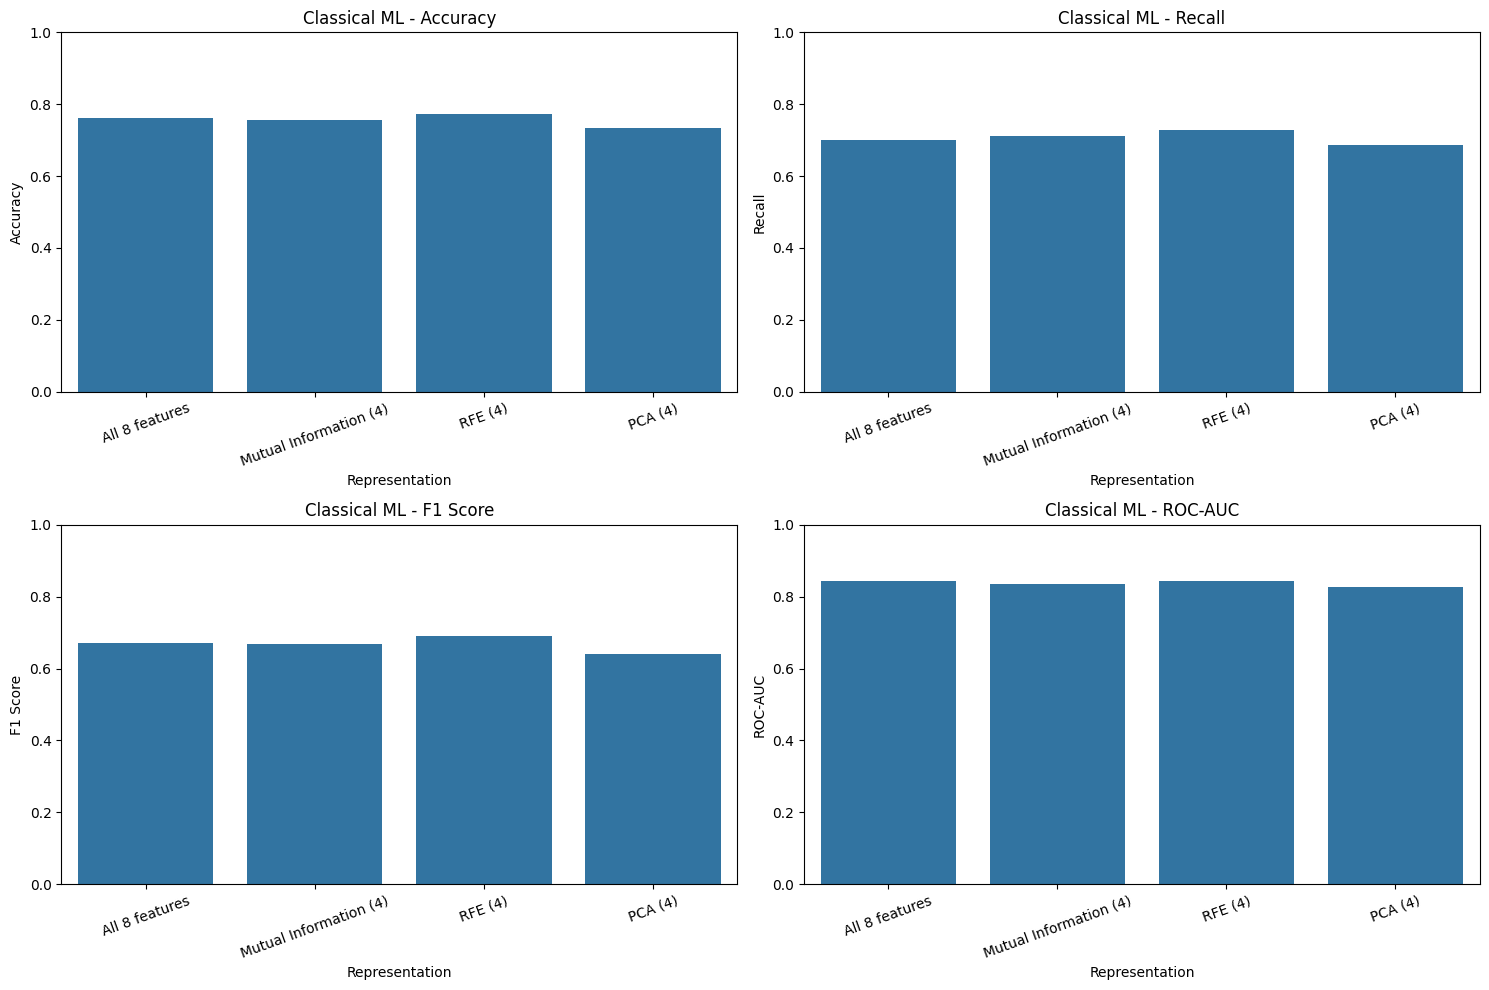

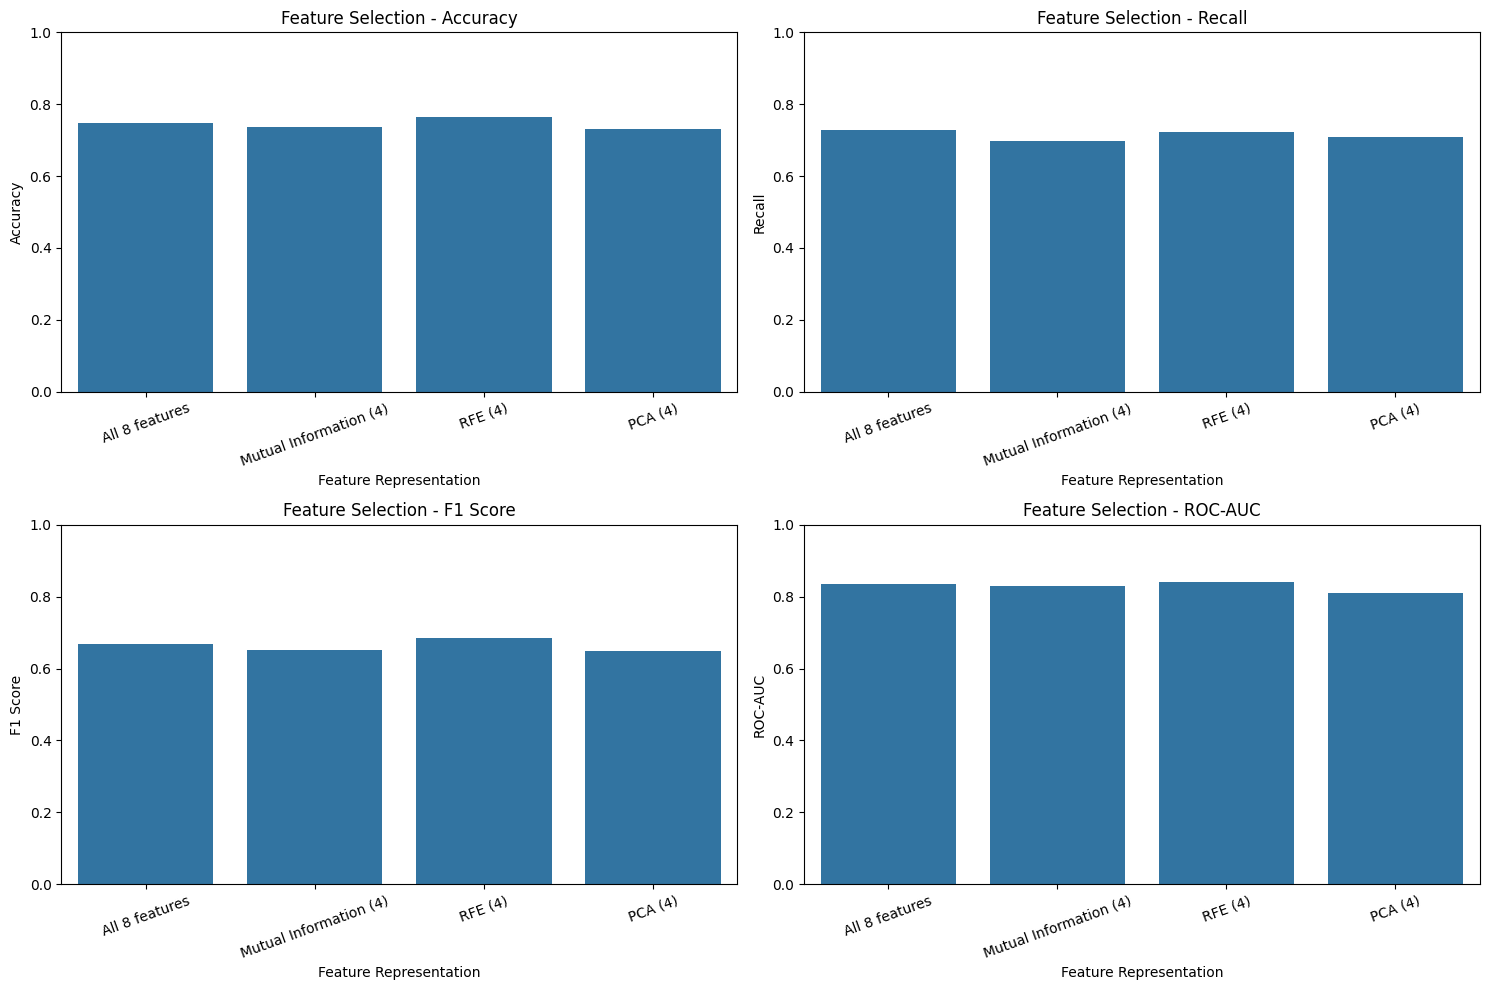


Cross-validation analysis completed.
Plots saved in: /content/results


In [7]:

# ============================================
# CELL 2: CROSS-VALIDATION PERFORMANCE ANALYSIS
# ============================================

# Classical ML results
print("CLASSICAL MACHINE LEARNING - 5-FOLD CV")
display(classical_results)

# Feature selection results
print("\nFEATURE SELECTION - 5-FOLD CV")
display(feature_results)

# Plot classical ML cross-validation metrics
classical_metrics = {
    "Accuracy": "accuracy_mean",
    "Recall": "recall_mean",
    "F1 Score": "f1_mean",
    "ROC-AUC": "roc_auc_mean"
}

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for ax, (metric_name, column) in zip(axes, classical_metrics.items()):
    sns.barplot(
        data=classical_results,
        x="representation",
        y=column,
        ax=ax
    )
    ax.set_title(f"Classical ML - {metric_name}")
    ax.set_xlabel("Representation")
    ax.set_ylabel(metric_name)
    ax.tick_params(axis="x", rotation=20)
    ax.set_ylim(0, 1)

plt.tight_layout()
plt.savefig(RESULTS / "classical_cv_comparison.png", dpi=300)
plt.show()

# Plot feature-selection cross-validation metrics
feature_metrics = {
    "Accuracy": "accuracy",
    "Recall": "recall",
    "F1 Score": "f1",
    "ROC-AUC": "roc_auc"
}

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
axes = axes.flatten()

for ax, (metric_name, column) in zip(axes, feature_metrics.items()):
    sns.barplot(
        data=feature_results,
        x="representation",
        y=column,
        ax=ax
    )
    ax.set_title(f"Feature Selection - {metric_name}")
    ax.set_xlabel("Feature Representation")
    ax.set_ylabel(metric_name)
    ax.tick_params(axis="x", rotation=20)
    ax.set_ylim(0, 1)

plt.tight_layout()
plt.savefig(RESULTS / "feature_selection_cv_comparison.png", dpi=300)
plt.show()

print("\nCross-validation analysis completed.")
print("Plots saved in:", RESULTS)

**Cell 3 – Quantum model performance analysis**

QUANTUM MODEL - HELD-OUT TEST RESULTS


,model,accuracy,precision,recall,f1_score,f2_score,roc_auc,pr_auc,specificity,execution_time_seconds,quantum_training_samples,test_samples
0,QSVM,0.720779,0.579710,0.740741,0.650407,0.701754,0.797593,0.660188,0.71,498.38,250,154
1,VQC,0.623377,0.452381,0.351852,0.395833,0.368217,0.654444,0.456586,0.77,165.77,250,154


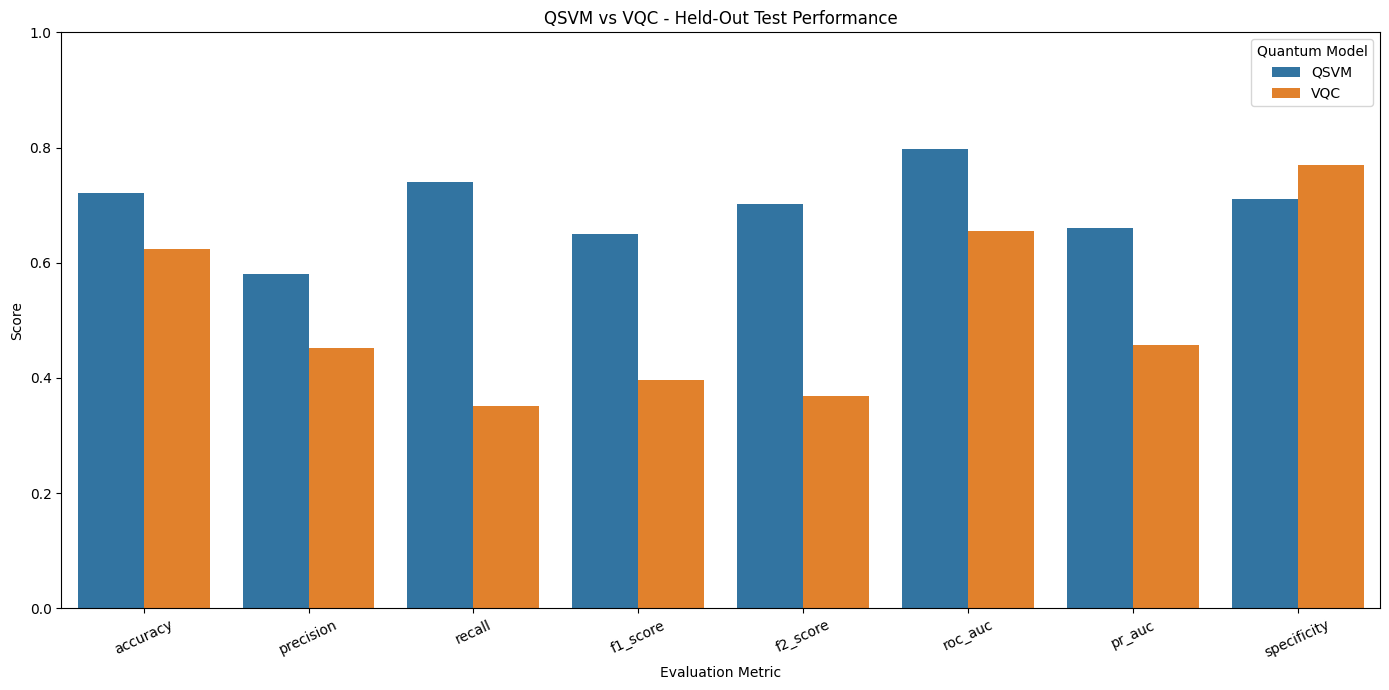

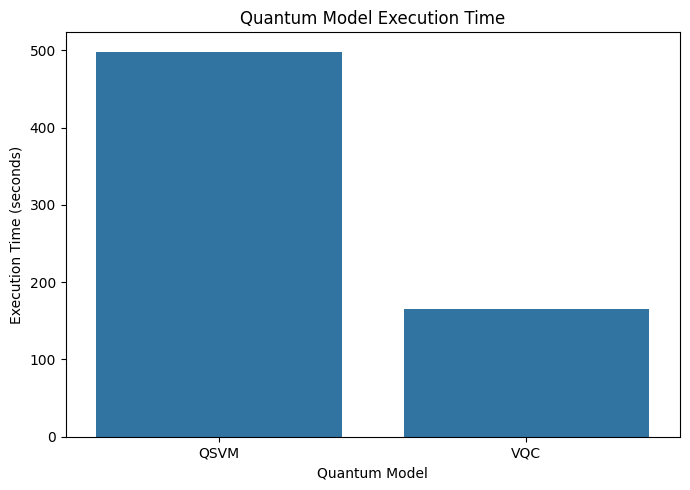


Quantum model analysis completed.


In [8]:

# ============================================
# CELL 3: QUANTUM MODEL PERFORMANCE ANALYSIS
# ============================================

quantum_results = pd.concat(
    [qsvm_results, vqc_results],
    ignore_index=True
)

quantum_metrics = [
    "accuracy",
    "precision",
    "recall",
    "f1_score",
    "f2_score",
    "roc_auc",
    "pr_auc",
    "specificity"
]

print("QUANTUM MODEL - HELD-OUT TEST RESULTS")
display(quantum_results[
    ["model"] + quantum_metrics +
    ["execution_time_seconds", "quantum_training_samples", "test_samples"]
])

# Convert metrics into percentage values for plotting
plot_data = quantum_results.melt(
    id_vars="model",
    value_vars=quantum_metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=plot_data,
    x="Metric",
    y="Score",
    hue="model"
)

plt.title("QSVM vs VQC - Held-Out Test Performance")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=25)
plt.legend(title="Quantum Model")
plt.tight_layout()

plt.savefig(
    RESULTS / "quantum_model_comparison.png",
    dpi=300
)

plt.show()

# Execution time comparison
plt.figure(figsize=(7, 5))

sns.barplot(
    data=quantum_results,
    x="model",
    y="execution_time_seconds"
)

plt.title("Quantum Model Execution Time")
plt.xlabel("Quantum Model")
plt.ylabel("Execution Time (seconds)")
plt.tight_layout()

plt.savefig(
    RESULTS / "quantum_execution_time.png",
    dpi=300
)

plt.show()

print("\nQuantum model analysis completed.")

**Cell 4 – Confusion matrices and error analysis**

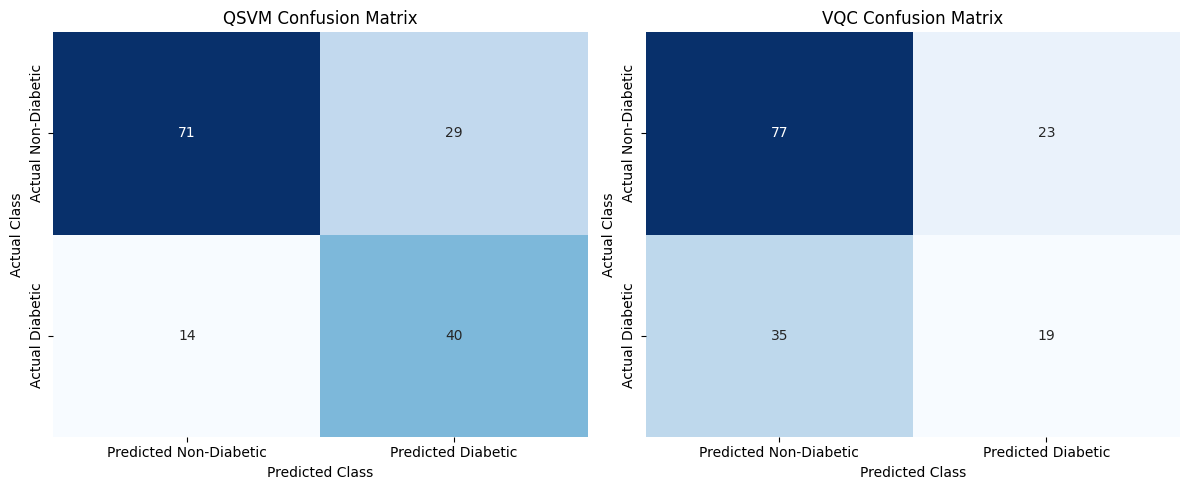

QUANTUM MODEL ERROR ANALYSIS


,model,true_positive,true_negative,false_positive,false_negative,total_errors
0,QSVM,40,71,29,14,43
1,VQC,19,77,23,35,58



Interpretation:
False Negative: A diabetic patient incorrectly classified as non-diabetic.
False Positive: A non-diabetic patient incorrectly classified as diabetic.


In [9]:

# ============================================
# CELL 4: QUANTUM MODEL CONFUSION MATRIX ANALYSIS
# ============================================

from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (_, row) in zip(axes, quantum_results.iterrows()):

    cm = np.array([
        [row["true_negative"], row["false_positive"]],
        [row["false_negative"], row["true_positive"]]
    ], dtype=int)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        xticklabels=["Predicted Non-Diabetic", "Predicted Diabetic"],
        yticklabels=["Actual Non-Diabetic", "Actual Diabetic"],
        ax=ax
    )

    ax.set_title(f'{row["model"]} Confusion Matrix')
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()

plt.savefig(
    RESULTS / "quantum_confusion_matrices.png",
    dpi=300
)

plt.show()

# Compare classification errors
error_analysis = quantum_results[
    ["model", "true_positive", "true_negative",
     "false_positive", "false_negative"]
].copy()

error_analysis["total_errors"] = (
    error_analysis["false_positive"] +
    error_analysis["false_negative"]
)

print("QUANTUM MODEL ERROR ANALYSIS")
display(error_analysis)

print("\nInterpretation:")
print("False Negative: A diabetic patient incorrectly classified as non-diabetic.")
print("False Positive: A non-diabetic patient incorrectly classified as diabetic.")

**Cell 5 – Reliability and error-rate analysis**

QUANTUM MODEL RELIABILITY INDICATORS


,model,sensitivity,specificity,false_negative_rate,false_positive_rate,balanced_accuracy,negative_predictive_value
0,QSVM,0.7407,0.71,0.2593,0.29,0.7254,0.8353
1,VQC,0.3519,0.77,0.6481,0.23,0.5609,0.6875


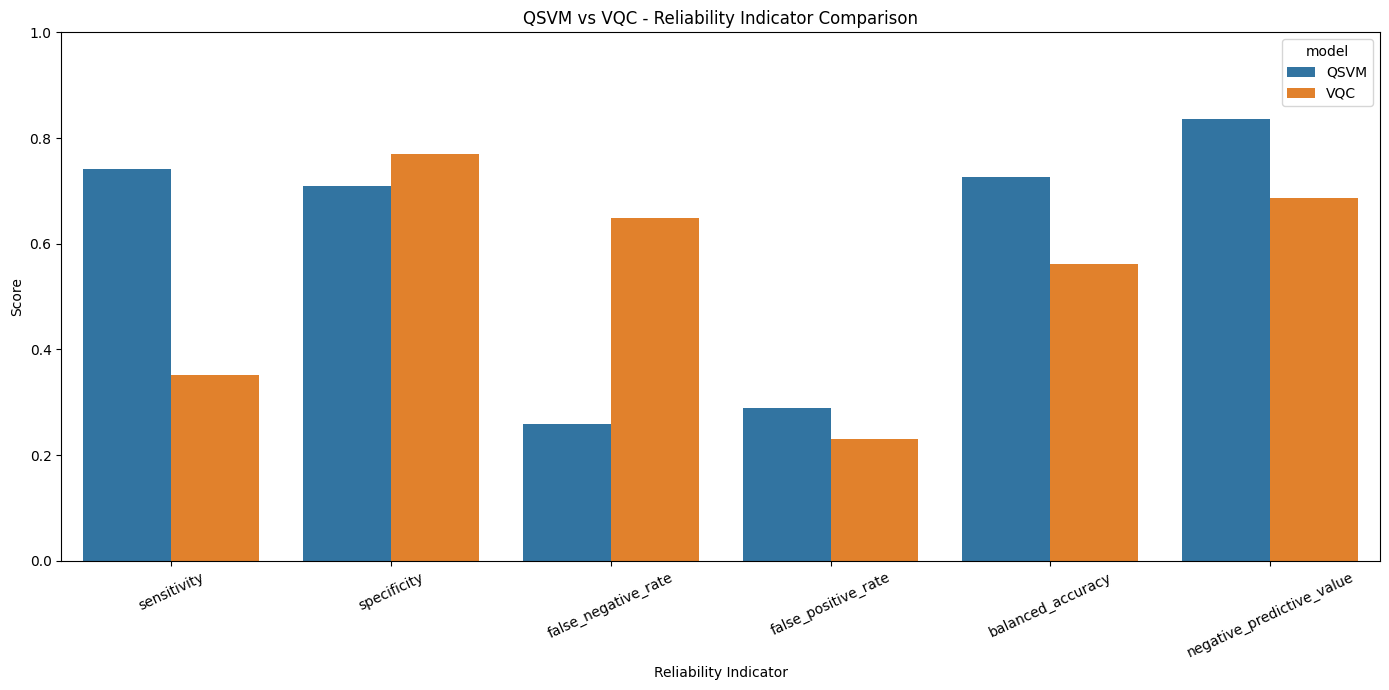

Reliability analysis saved successfully.


In [10]:

# ============================================
# CELL 5: RELIABILITY AND ERROR-RATE ANALYSIS
# ============================================

reliability_records = []

for _, row in quantum_results.iterrows():

    TP = row["true_positive"]
    TN = row["true_negative"]
    FP = row["false_positive"]
    FN = row["false_negative"]

    sensitivity = TP / (TP + FN)
    specificity = TN / (TN + FP)

    fnr = FN / (FN + TP)
    fpr = FP / (FP + TN)

    balanced_accuracy = (sensitivity + specificity) / 2

    npv = TN / (TN + FN)

    reliability_records.append({
        "model": row["model"],
        "sensitivity": sensitivity,
        "specificity": specificity,
        "false_negative_rate": fnr,
        "false_positive_rate": fpr,
        "balanced_accuracy": balanced_accuracy,
        "negative_predictive_value": npv
    })

reliability_df = pd.DataFrame(reliability_records)

print("QUANTUM MODEL RELIABILITY INDICATORS")
display(reliability_df.round(4))

# Plot reliability indicators
plot_reliability = reliability_df.melt(
    id_vars="model",
    var_name="Reliability Metric",
    value_name="Score"
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=plot_reliability,
    x="Reliability Metric",
    y="Score",
    hue="model"
)

plt.title("QSVM vs VQC - Reliability Indicator Comparison")
plt.xlabel("Reliability Indicator")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=25)
plt.tight_layout()

plt.savefig(
    RESULTS / "quantum_reliability_analysis.png",
    dpi=300
)

plt.show()

# Save numerical results
reliability_df.to_csv(
    RESULTS / "quantum_reliability_analysis.csv",
    index=False
)

print("Reliability analysis saved successfully.")

**Cell 6 – Consolidated quantum model comparison**

CONSOLIDATED QUANTUM MODEL COMPARISON


,model,accuracy,precision,recall,f1_score,f2_score,roc_auc,pr_auc,specificity,false_negative_rate,false_positive_rate,balanced_accuracy,negative_predictive_value,execution_time_seconds
0,QSVM,0.7208,0.5797,0.7407,0.6504,0.7018,0.7976,0.6602,0.71,0.2593,0.29,0.7254,0.8353,498.38
1,VQC,0.6234,0.4524,0.3519,0.3958,0.3682,0.6544,0.4566,0.77,0.6481,0.23,0.5609,0.6875,165.77


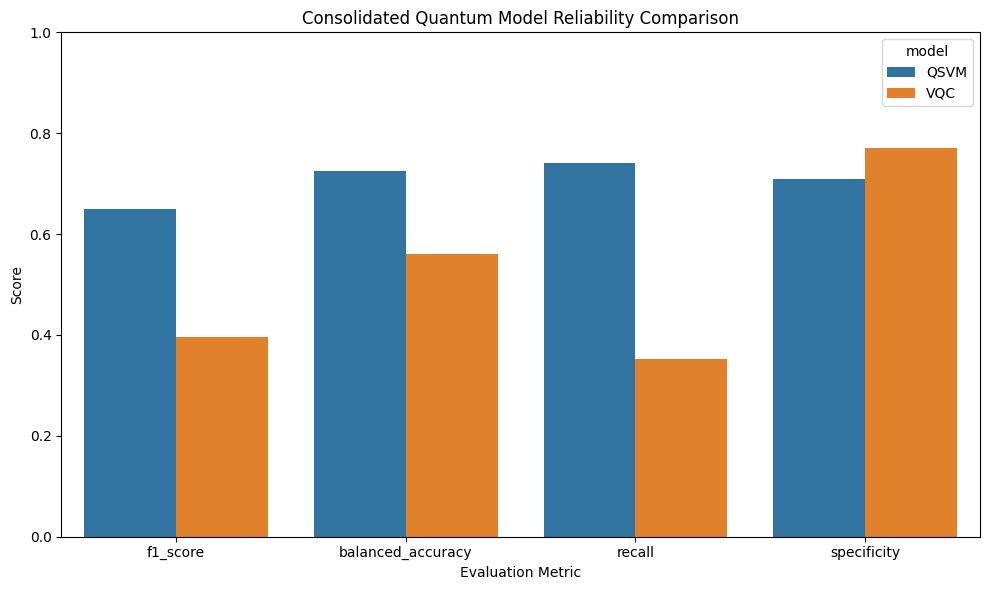

Consolidated quantum comparison saved successfully.


In [14]:

# ============================================
# CELL 6: CONSOLIDATED QUANTUM MODEL ANALYSIS
# ============================================

# Remove duplicate specificity from the original results
quantum_base = quantum_results.drop(
    columns=["specificity"],
    errors="ignore"
)

# Merge performance metrics with reliability metrics
quantum_summary = quantum_base.merge(
    reliability_df,
    on="model",
    how="inner"
)

summary_columns = [
    "model",
    "accuracy",
    "precision",
    "recall",
    "f1_score",
    "f2_score",
    "roc_auc",
    "pr_auc",
    "specificity",
    "false_negative_rate",
    "false_positive_rate",
    "balanced_accuracy",
    "negative_predictive_value",
    "execution_time_seconds"
]

quantum_summary = quantum_summary[summary_columns]

print("CONSOLIDATED QUANTUM MODEL COMPARISON")
display(quantum_summary.round(4))

# Save consolidated results
quantum_summary.to_csv(
    RESULTS / "quantum_consolidated_comparison.csv",
    index=False
)



# Compare important performance and reliability metrics
comparison_metrics = [
    "f1_score",
    "balanced_accuracy",
    "recall",
    "specificity"
]

comparison_plot = quantum_summary.melt(
    id_vars="model",
    value_vars=comparison_metrics,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=comparison_plot,
    x="Metric",
    y="Score",
    hue="model"
)

plt.title("Consolidated Quantum Model Reliability Comparison")
plt.xlabel("Evaluation Metric")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.tight_layout()

plt.savefig(
    RESULTS / "quantum_consolidated_comparison.png",
    dpi=300
)

plt.show()

print("Consolidated quantum comparison saved successfully.")


**Cell 7 – Rebuild classical models and evaluate on the same test set**

In [16]:

# ============================================
# CELL 7: CLASSICAL MODELS - HELD-OUT TEST EVALUATION
# ============================================

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, fbeta_score, roc_auc_score,
    average_precision_score, confusion_matrix
)

# Load original dataset
DATA_PATH = Path("/content/diabetes.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError("diabetes.csv not found at /content/diabetes.csv")

df = pd.read_csv(DATA_PATH)

TARGET = "Outcome"
INVALID_ZERO_COLS = [
    "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI"
]

X = df.drop(columns=TARGET).copy()
y = df[TARGET].astype(int).copy()

# Replace invalid zeros with missing values
X[INVALID_ZERO_COLS] = X[INVALID_ZERO_COLS].replace(0, np.nan)

# Reproduce the same split used in quantum experiments
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

# Define the four classical models
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=42
    ),

    "RBF-SVM": SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        class_weight="balanced",
        probability=True,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

classical_test_records = []
classical_confusion_matrices = {}

for name, model in models.items():

    steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if name in ["Logistic Regression", "RBF-SVM"]:
        steps.append(("scaler", StandardScaler()))

    pipeline = Pipeline(steps + [("model", model)])

    # Train on training data only
    pipeline.fit(X_train, y_train)

    # Predict on the common held-out test set
    y_pred = pipeline.predict(X_test)
    y_scores = pipeline.predict_proba(X_test)[:, 1]

    # Confusion matrix
    tn, fp, fn, tp = confusion_matrix(
        y_test, y_pred, labels=[0, 1]
    ).ravel()

    sensitivity = tp / (tp + fn) if (tp + fn) else 0
    specificity = tn / (tn + fp) if (tn + fp) else 0
    fnr = fn / (fn + tp) if (fn + tp) else 0
    fpr = fp / (fp + tn) if (fp + tn) else 0
    npv = tn / (tn + fn) if (tn + fn) else 0

    record = {
        "model": name,
        "accuracy": accuracy_score(y_test, y_pred),
        "precision": precision_score(y_test, y_pred, zero_division=0),
        "recall": recall_score(y_test, y_pred, zero_division=0),
        "f1_score": f1_score(y_test, y_pred, zero_division=0),
        "f2_score": fbeta_score(y_test, y_pred, beta=2, zero_division=0),
        "roc_auc": roc_auc_score(y_test, y_scores),
        "pr_auc": average_precision_score(y_test, y_scores),
        "specificity": specificity,
        "false_negative_rate": fnr,
        "false_positive_rate": fpr,
        "balanced_accuracy": (sensitivity + specificity) / 2,
        "negative_predictive_value": npv,
        "true_negative": tn,
        "false_positive": fp,
        "false_negative": fn,
        "true_positive": tp,
        "training_samples": len(X_train),
        "test_samples": len(X_test)
    }

    classical_test_records.append(record)
    classical_confusion_matrices[name] = np.array([[tn, fp], [fn, tp]])

classical_test_results = pd.DataFrame(classical_test_records)

print("\nCLASSICAL MODELS - HELD-OUT TEST RESULTS")
display(classical_test_results.round(4))

# Save results
classical_test_results.to_csv(
    RESULTS / "classical_test_results.csv",
    index=False
)

print("Saved:", RESULTS / "classical_test_results.csv")


Training samples: 614
Test samples: 154

CLASSICAL MODELS - HELD-OUT TEST RESULTS


,model,accuracy,precision,recall,f1_score,f2_score,roc_auc,pr_auc,specificity,false_negative_rate,false_positive_rate,balanced_accuracy,negative_predictive_value,true_negative,false_positive,false_negative,true_positive,training_samples,test_samples
0,Logistic Regression,0.7338,0.6032,0.7037,0.6496,0.6810,0.8126,0.6727,0.75,0.2963,0.25,0.7269,0.8242,75,25,16,38,614,154
1,Random Forest,0.7597,0.6667,0.6296,0.6476,0.6367,0.8244,0.7090,0.83,0.3704,0.17,0.7298,0.8058,83,17,20,34,614,154
2,RBF-SVM,0.7273,0.5909,0.7222,0.6500,0.6915,0.8139,0.6774,0.73,0.2778,0.27,0.7261,0.8295,73,27,15,39,614,154
3,Gradient Boosting,0.7597,0.6889,0.5741,0.6263,0.5939,0.8315,0.7251,0.86,0.4259,0.14,0.7170,0.7890,86,14,23,31,614,154


Saved: /content/results/classical_test_results.csv


**Cell 8 – Consolidated Classical vs Quantum Comparison**

CLASSICAL VS QUANTUM - HELD-OUT TEST RESULTS


,model,accuracy,precision,recall,f1_score,f2_score,roc_auc,pr_auc,specificity,false_negative_rate,false_positive_rate,balanced_accuracy,negative_predictive_value,training_samples,quantum_training_samples,test_samples,execution_time_seconds
0,Logistic Regression,0.7338,0.6032,0.7037,0.6496,0.6810,0.8126,0.6727,0.75,0.2963,0.25,0.7269,0.8242,614,NaN,154,NaN
1,Random Forest,0.7597,0.6667,0.6296,0.6476,0.6367,0.8244,0.7090,0.83,0.3704,0.17,0.7298,0.8058,614,NaN,154,NaN
2,RBF-SVM,0.7273,0.5909,0.7222,0.6500,0.6915,0.8139,0.6774,0.73,0.2778,0.27,0.7261,0.8295,614,NaN,154,NaN
3,Gradient Boosting,0.7597,0.6889,0.5741,0.6263,0.5939,0.8315,0.7251,0.86,0.4259,0.14,0.7170,0.7890,614,NaN,154,NaN
4,QSVM,0.7208,0.5797,0.7407,0.6504,0.7018,0.7976,0.6602,0.71,NaN,NaN,NaN,NaN,614,250.0,154,498.38
5,VQC,0.6234,0.4524,0.3519,0.3958,0.3682,0.6544,0.4566,0.77,NaN,NaN,NaN,NaN,614,250.0,154,165.77


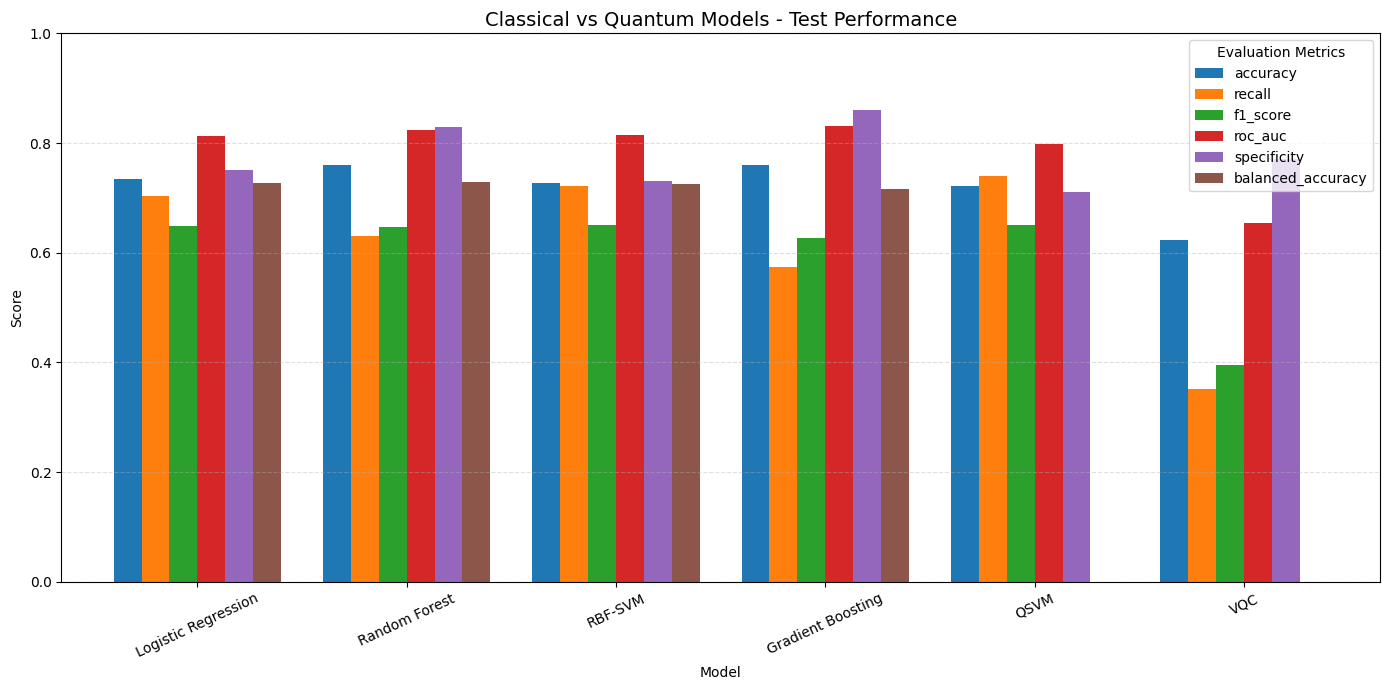


Saved files:
/content/results/classical_quantum_test_comparison.csv
/content/results/classical_quantum_test_comparison.png

IMPORTANT EXPERIMENTAL NOTES
- All six models are evaluated on the same 154 held-out test samples.
- Classical models are trained using all 614 training samples.
- Quantum models use a 250-sample subset for quantum training.
- Classical pipelines use median imputation.
- Quantum pipelines use KNN imputation and MI-based selection of 4 features.
- Therefore, this is a same-test-set comparison, but not a fully controlled
  comparison of model architecture alone.


In [17]:

# ============================================
# CELL 8: CLASSICAL VS QUANTUM COMPARISON
# ============================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# 1. Select common evaluation metrics
comparison_columns = [
    "model",
    "accuracy",
    "precision",
    "recall",
    "f1_score",
    "f2_score",
    "roc_auc",
    "pr_auc",
    "specificity",
    "false_negative_rate",
    "false_positive_rate",
    "balanced_accuracy",
    "negative_predictive_value",
    "execution_time_seconds",
    "training_samples",
    "quantum_training_samples",
    "test_samples"
]

# 2. Prepare classical results
classical_comparison = classical_test_results.copy()

# Standardize the F1/F2 and model column names if needed
classical_comparison = classical_comparison.rename(columns={
    "f1": "f1_score",
    "f2": "f2_score",
    "balanced_acc": "balanced_accuracy",
    "model": "model"
})

if "model" not in classical_comparison.columns:
    classical_comparison = classical_comparison.rename(
        columns={"Model": "model"}
    )

# Classical models do not use a quantum subset
if "quantum_training_samples" not in classical_comparison.columns:
    classical_comparison["quantum_training_samples"] = np.nan

# 3. Prepare quantum results
quantum_comparison = quantum_results.copy()

# 4. Keep only columns available in each dataset
classical_comparison = classical_comparison[
    [c for c in comparison_columns if c in classical_comparison.columns]
]

quantum_comparison = quantum_comparison[
    [c for c in comparison_columns if c in quantum_comparison.columns]
]

# 5. Combine all six models
all_models_test_results = pd.concat(
    [classical_comparison, quantum_comparison],
    ignore_index=True
)

# 6. Display consolidated results
print("CLASSICAL VS QUANTUM - HELD-OUT TEST RESULTS")
display(all_models_test_results.round(4))

# 7. Plot selected performance metrics
plot_metrics = [
    "accuracy",
    "recall",
    "f1_score",
    "roc_auc",
    "specificity",
    "balanced_accuracy"
]

available_metrics = [
    metric for metric in plot_metrics
    if metric in all_models_test_results.columns
]

ax = all_models_test_results.set_index("model")[
    available_metrics
].plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8
)

ax.set_title(
    "Classical vs Quantum Models - Test Performance",
    fontsize=14
)
ax.set_ylabel("Score")
ax.set_xlabel("Model")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=25)
ax.legend(title="Evaluation Metrics")
ax.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()

# 8. Save comparison outputs
os.makedirs("/content/results", exist_ok=True)

csv_path = "/content/results/classical_quantum_test_comparison.csv"
graph_path = "/content/results/classical_quantum_test_comparison.png"

all_models_test_results.to_csv(csv_path, index=False)
plt.savefig(graph_path, dpi=300, bbox_inches="tight")
plt.show()

print("\nSaved files:")
print(csv_path)
print(graph_path)

# 9. Experimental comparison notes
print("\nIMPORTANT EXPERIMENTAL NOTES")
print("- All six models are evaluated on the same 154 held-out test samples.")
print("- Classical models are trained using all 614 training samples.")
print("- Quantum models use a 250-sample subset for quantum training.")
print("- Classical pipelines use median imputation.")
print("- Quantum pipelines use KNN imputation and MI-based selection of 4 features.")
print("- Therefore, this is a same-test-set comparison, but not a fully controlled")
print("  comparison of model architecture alone.")


**CELL 8A: COMPLETE QUANTUM RELIABILITY METRICS**

In [18]:

# CELL 8A: COMPLETE QUANTUM RELIABILITY METRICS

reliability_df = pd.read_csv(
    "/content/results/quantum_reliability_analysis.csv"
)

reliability_columns = [
    "model",
    "false_negative_rate",
    "false_positive_rate",
    "balanced_accuracy",
    "negative_predictive_value"
]

reliability_to_merge = reliability_df[
    [c for c in reliability_columns if c in reliability_df.columns]
].copy()

# Update quantum rows in the consolidated comparison
for metric in reliability_columns[1:]:
    if metric in reliability_to_merge.columns:
        metric_map = reliability_to_merge.set_index("model")[metric]
        mask = all_models_test_results["model"].isin(metric_map.index)

        all_models_test_results.loc[mask, metric] = (
            all_models_test_results.loc[mask, "model"].map(metric_map)
        )

# Save corrected results
all_models_test_results.to_csv(
    "/content/results/classical_quantum_test_comparison.csv",
    index=False
)

print("CORRECTED CLASSICAL VS QUANTUM COMPARISON")
display(all_models_test_results.round(4))

print("\nUpdated CSV saved successfully.")


CORRECTED CLASSICAL VS QUANTUM COMPARISON


,model,accuracy,precision,recall,f1_score,f2_score,roc_auc,pr_auc,specificity,false_negative_rate,false_positive_rate,balanced_accuracy,negative_predictive_value,training_samples,quantum_training_samples,test_samples,execution_time_seconds
0,Logistic Regression,0.7338,0.6032,0.7037,0.6496,0.6810,0.8126,0.6727,0.75,0.2963,0.25,0.7269,0.8242,614,NaN,154,NaN
1,Random Forest,0.7597,0.6667,0.6296,0.6476,0.6367,0.8244,0.7090,0.83,0.3704,0.17,0.7298,0.8058,614,NaN,154,NaN
2,RBF-SVM,0.7273,0.5909,0.7222,0.6500,0.6915,0.8139,0.6774,0.73,0.2778,0.27,0.7261,0.8295,614,NaN,154,NaN
3,Gradient Boosting,0.7597,0.6889,0.5741,0.6263,0.5939,0.8315,0.7251,0.86,0.4259,0.14,0.7170,0.7890,614,NaN,154,NaN
4,QSVM,0.7208,0.5797,0.7407,0.6504,0.7018,0.7976,0.6602,0.71,0.2593,0.29,0.7254,0.8353,614,250.0,154,498.38
5,VQC,0.6234,0.4524,0.3519,0.3958,0.3682,0.6544,0.4566,0.77,0.6481,0.23,0.5609,0.6875,614,250.0,154,165.77



Updated CSV saved successfully.


**Cell 9 – Confusion Matrix Comparison (All Six Models)**

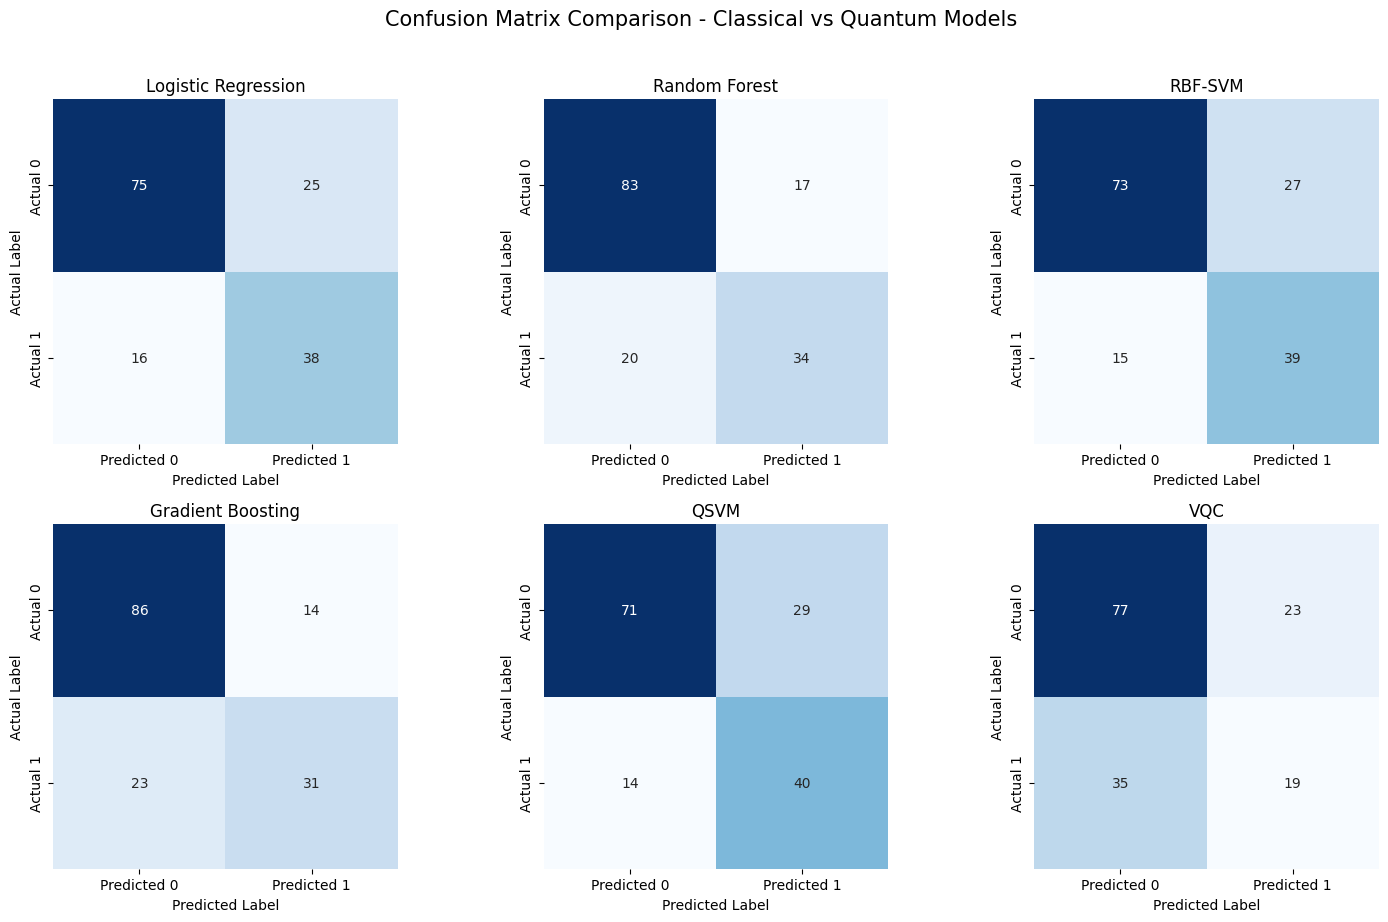


CONFUSION MATRIX ERROR SUMMARY


,model,true_negative,false_positive,false_negative,true_positive,total_errors
0,Logistic Regression,75,25,16,38,41
1,Random Forest,83,17,20,34,37
2,RBF-SVM,73,27,15,39,42
3,Gradient Boosting,86,14,23,31,37
4,QSVM,71,29,14,40,43
5,VQC,77,23,35,19,58



Saved: /content/results/all_models_confusion_matrices.png


In [20]:

# ============================================
# CELL 9: CONFUSION MATRICES FOR ALL SIX MODELS
# ============================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# 1. Load classical and quantum test results
classical_cm = classical_test_results.copy()
quantum_cm = quantum_results.copy()

# Standardize classical column names
classical_cm = classical_cm.rename(columns={
    "Model": "model",
    "balanced_acc": "balanced_accuracy"
})

# Standardize model name
if "model" not in classical_cm.columns:
    classical_cm = classical_cm.rename(columns={"Model": "model"})

# 2. Combine results
cm_results = pd.concat(
    [classical_cm, quantum_cm],
    ignore_index=True,
    sort=False
)

# 3. Create confusion matrices using TN, FP, FN, TP
models = cm_results["model"].tolist()

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, (_, row) in enumerate(cm_results.iterrows()):

    tn = int(row["true_negative"])
    fp = int(row["false_positive"])
    fn = int(row["false_negative"])
    tp = int(row["true_positive"])

    cm = [[tn, fp],
          [fn, tp]]

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        square=True,
        xticklabels=["Predicted 0", "Predicted 1"],
        yticklabels=["Actual 0", "Actual 1"],
        ax=axes[i]
    )

    axes[i].set_title(row["model"])
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("Actual Label")

plt.suptitle(
    "Confusion Matrix Comparison - Classical vs Quantum Models",
    fontsize=15,
    y=1.02
)

plt.tight_layout()

# 4. Save graph
os.makedirs("/content/results", exist_ok=True)

cm_path = "/content/results/all_models_confusion_matrices.png"

plt.savefig(cm_path, dpi=300, bbox_inches="tight")
plt.show()

# 5. Display error summary
cm_results["total_errors"] = (
    cm_results["false_positive"] +
    cm_results["false_negative"]
)

error_summary = cm_results[
    ["model", "true_negative", "false_positive",
     "false_negative", "true_positive", "total_errors"]
]

print("\nCONFUSION MATRIX ERROR SUMMARY")
display(error_summary)

print("\nSaved:", cm_path)


**Cell 10 – Final Experimental Findings and Observations**

In [21]:

# ============================================
# CELL 10: FINAL EXPERIMENTAL FINDINGS
# ============================================

import pandas as pd
import numpy as np
import os

# Use consolidated six-model test results
final_results = all_models_test_results.copy()

# 1. Identify best model for each evaluation metric
metrics_to_analyze = [
    "accuracy",
    "precision",
    "recall",
    "f1_score",
    "f2_score",
    "roc_auc",
    "pr_auc",
    "specificity",
    "balanced_accuracy",
    "negative_predictive_value"
]

findings = []

for metric in metrics_to_analyze:
    if metric in final_results.columns:
        best_idx = final_results[metric].astype(float).idxmax()
        findings.append({
            "metric": metric,
            "best_model": final_results.loc[best_idx, "model"],
            "best_score": final_results.loc[best_idx, metric]
        })

best_models_summary = pd.DataFrame(findings)

print("BEST MODEL BY EVALUATION METRIC")
display(best_models_summary.round(4))

# 2. Identify lowest false-negative model
lowest_fn_idx = final_results["false_negative_rate"].astype(float).idxmin()

print("\nLOWEST FALSE-NEGATIVE RATE")
print("Model:", final_results.loc[lowest_fn_idx, "model"])
print("FNR:", round(final_results.loc[lowest_fn_idx, "false_negative_rate"], 4))

# 3. Identify fastest quantum model
quantum_only = final_results[
    final_results["model"].isin(["QSVM", "VQC"])
]

fastest_quantum_idx = quantum_only[
    "execution_time_seconds"
].astype(float).idxmin()

print("\nFASTEST QUANTUM MODEL")
print("Model:", final_results.loc[fastest_quantum_idx, "model"])
print(
    "Execution time:",
    final_results.loc[fastest_quantum_idx, "execution_time_seconds"],
    "seconds"
)

# 4. Generate experimental observations
observations = [
    "All six models were evaluated on the same 154 held-out test samples.",
    "Classical models were trained using 614 training samples.",
    "Quantum models used a 250-sample subset for quantum training.",
    "QSVM achieved the highest recall among the evaluated models.",
    "QSVM produced the lowest number of false negatives.",
    "Gradient Boosting achieved the highest ROC-AUC and specificity.",
    "Random Forest and Gradient Boosting achieved the highest accuracy.",
    "VQC showed lower performance than the other evaluated models.",
    "Quantum models were evaluated using a simulator, not quantum hardware.",
    "Differences in training sample size and preprocessing should be considered.",
    "The experiments do not establish quantum advantage or clinical readiness."
]

print("\nFINAL EXPERIMENTAL OBSERVATIONS")
for i, observation in enumerate(observations, 1):
    print(f"{i}. {observation}")

# 5. Save final outputs
os.makedirs("/content/results", exist_ok=True)

best_models_summary.to_csv(
    "/content/results/best_models_summary.csv",
    index=False
)

with open(
    "/content/results/final_experimental_observations.txt",
    "w"
) as file:
    file.write("FINAL EXPERIMENTAL OBSERVATIONS\n\n")
    for i, observation in enumerate(observations, 1):
        file.write(f"{i}. {observation}\n")

print("\nSaved:")
print("/content/results/best_models_summary.csv")
print("/content/results/final_experimental_observations.txt")


BEST MODEL BY EVALUATION METRIC


,metric,best_model,best_score
0,accuracy,Random Forest,0.7597
1,precision,Gradient Boosting,0.6889
2,recall,QSVM,0.7407
3,f1_score,QSVM,0.6504
4,f2_score,QSVM,0.7018
5,roc_auc,Gradient Boosting,0.8315
6,pr_auc,Gradient Boosting,0.7251
7,specificity,Gradient Boosting,0.8600
8,balanced_accuracy,Random Forest,0.7298
9,negative_predictive_value,QSVM,0.8353



LOWEST FALSE-NEGATIVE RATE
Model: QSVM
FNR: 0.2593

FASTEST QUANTUM MODEL
Model: VQC
Execution time: 165.77 seconds

FINAL EXPERIMENTAL OBSERVATIONS
1. All six models were evaluated on the same 154 held-out test samples.
2. Classical models were trained using 614 training samples.
3. Quantum models used a 250-sample subset for quantum training.
4. QSVM achieved the highest recall among the evaluated models.
5. QSVM produced the lowest number of false negatives.
6. Gradient Boosting achieved the highest ROC-AUC and specificity.
7. Random Forest and Gradient Boosting achieved the highest accuracy.
8. VQC showed lower performance than the other evaluated models.
9. Quantum models were evaluated using a simulator, not quantum hardware.
10. Differences in training sample size and preprocessing should be considered.
11. The experiments do not establish quantum advantage or clinical readiness.

Saved:
/content/results/best_models_summary.csv
/content/results/final_experimental_observations.t

In [22]:

from pathlib import Path

results_dir = Path("/content/results")

rename_map = {
    "classical_cv.CSV": "classical_cv.csv",
    "feature selection cv.csv": "feature_selection_cv.csv",
    "qsvm results.csv": "qsvm_results.csv",
    "vqc results.csv": "vqc_results.csv",
    "Es quantum_reliability_analysis.csv": "quantum_reliability_analysis.csv",
    "quantum_consolidated comparison.csv": "quantum_consolidated_comparison.csv",
    "classical test results.csv": "classical_test_results.csv",
    "classical quantum_test_comparison.csv": "classical_quantum_test_comparison.csv"
}

for old_name, new_name in rename_map.items():
    old_path = results_dir / old_name
    new_path = results_dir / new_name

    if old_path.exists():
        if new_path.exists():
            print(f"Already exists, skipping: {new_name}")
        else:
            old_path.rename(new_path)
            print(f"Renamed: {old_name} -> {new_name}")
    elif new_path.exists():
        print(f"Already correctly named: {new_name}")
    else:
        print(f"NOT FOUND: {old_name}")

print("\nFINAL RESULTS FOLDER")
for file in sorted(results_dir.iterdir()):
    if file.is_file():
        print(file.name)


Already correctly named: classical_cv.csv
Already correctly named: feature_selection_cv.csv
Already correctly named: qsvm_results.csv
Already correctly named: vqc_results.csv
Already correctly named: quantum_reliability_analysis.csv
Already correctly named: quantum_consolidated_comparison.csv
Already correctly named: classical_test_results.csv
Already correctly named: classical_quantum_test_comparison.csv

FINAL RESULTS FOLDER
all_models_confusion_matrices.png
best_models_summary.csv
classical_cv.csv
classical_cv_comparison.png
classical_quantum_test_comparison.csv
classical_quantum_test_comparison.png
classical_test_results.csv
feature_selection_cv.csv
feature_selection_cv_comparison.png
final_experimental_observations.txt
qsvm_results.csv
quantum_confusion_matrices.png
quantum_consolidated_comparison.csv
quantum_consolidated_comparison.png
quantum_execution_time.png
quantum_model_comparison.png
quantum_reliability_analysis.csv
quantum_reliability_analysis.png
vqc_results.csv


In [25]:

import base64
import requests
from pathlib import Path
from google.colab import userdata
from urllib.parse import quote
import time

# =====================================================
# 1. GITHUB CONFIGURATION
# =====================================================

GITHUB_TOKEN = userdata.get("GITHUB_TOKEN")

OWNER = "shahaanabbas-13"
REPO = "Quantum-Diabetes-Prediction"
BRANCH = "main"

LOCAL_DIR = Path("/content/results")

if not GITHUB_TOKEN:
    raise ValueError(
        "GITHUB_TOKEN not found in Colab Secrets. "
        "Add your GitHub token to Colab Secrets first."
    )

headers = {
    "Authorization": f"Bearer {GITHUB_TOKEN}",
    "Accept": "application/vnd.github+json",
    "X-GitHub-Api-Version": "2022-11-28"
}

# =====================================================
# 2. EXPECTED FILES
# =====================================================

expected_files = [
    "classical_cv.csv",
    "classical_cv_comparison.png",
    "feature_selection_cv.csv",
    "feature_selection_cv_comparison.png",
    "qsvm_results.csv",
    "vqc_results.csv",
    "quantum_model_comparison.png",
    "quantum_execution_time.png",
    "quantum_confusion_matrices.png",
    "quantum_reliability_analysis.csv",
    "quantum_reliability_analysis.png",
    "quantum_consolidated_comparison.csv",
    "quantum_consolidated_comparison.png",
    "classical_test_results.csv",
    "classical_quantum_test_comparison.csv",
    "classical_quantum_test_comparison.png",
    "all_models_confusion_matrices.png",
    "best_models_summary.csv",
    "final_experimental_observations.txt"
]

# =====================================================
# 3. CHECK LOCAL FILES
# =====================================================

print("=" * 65)
print("CHECKING LOCAL RESULTS FILES")
print("=" * 65)

present_files = []
missing_files = []

for filename in expected_files:
    local_file = LOCAL_DIR / filename

    if local_file.is_file():
        present_files.append(filename)
        print(f"[PRESENT] {filename}")
    else:
        missing_files.append(filename)
        print(f"[MISSING] {filename}")

print("\nExpected files:", len(expected_files))
print("Present files:", len(present_files))
print("Missing files:", len(missing_files))

if missing_files:
    print("\nCannot upload missing local files:")
    for filename in missing_files:
        print(" -", filename)

if not present_files:
    raise FileNotFoundError("No expected result files were found.")

# =====================================================
# 4. UPLOAD TO GITHUB
# =====================================================

print("\n" + "=" * 65)
print("UPLOADING FILES TO GITHUB")
print("=" * 65)

uploaded = []
updated = []
failed = []

for filename in present_files:

    local_file = LOCAL_DIR / filename
    github_path = f"results/{filename}"

    api_url = (
        f"https://api.github.com/repos/{OWNER}/{REPO}"
        f"/contents/{quote(github_path, safe='/')}"
    )

    try:
        # Read local file
        with open(local_file, "rb") as f:
            content = f.read()

        encoded_content = base64.b64encode(
            content
        ).decode("utf-8")

        # Check whether the file exists on GitHub
        check = requests.get(
            api_url,
            headers=headers,
            params={"ref": BRANCH},
            timeout=30
        )

        payload = {
            "message": f"Upload/update results/{filename}",
            "content": encoded_content,
            "branch": BRANCH
        }

        if check.status_code == 200:
            # Existing file: SHA is required for updating
            payload["sha"] = check.json()["sha"]
            action = "UPDATE"

        elif check.status_code == 404:
            # New file: create without SHA
            action = "CREATE"

        else:
            raise Exception(
                f"GitHub check failed: "
                f"{check.status_code} - {check.text}"
            )

        # Upload or update
        response = requests.put(
            api_url,
            headers=headers,
            json=payload,
            timeout=60
        )

        if response.status_code in [200, 201]:

            if action == "CREATE":
                uploaded.append(filename)
                print(f"[UPLOADED] {filename}")

            else:
                updated.append(filename)
                print(f"[UPDATED]  {filename}")

        else:
            failed.append(filename)
            print(
                f"[FAILED] {filename} | "
                f"{response.status_code} | {response.text}"
            )

    except Exception as e:
        failed.append(filename)
        print(f"[ERROR] {filename}: {e}")

    # Small delay between API requests
    time.sleep(0.2)

# =====================================================
# 5. FINAL SUMMARY
# =====================================================

print("\n" + "=" * 65)
print("FINAL GITHUB UPLOAD SUMMARY")
print("=" * 65)

print("Expected files:          ", len(expected_files))
print("Local files present:     ", len(present_files))
print("Missing local files:     ", len(missing_files))
print("New files uploaded:      ", len(uploaded))
print("Existing files updated: ", len(updated))
print("Upload failures:         ", len(failed))

print("\n")

if uploaded:
    print("NEWLY UPLOADED FILES:")
    for filename in uploaded:
        print("  +", filename)

if updated:
    print("\nUPDATED FILES:")
    for filename in updated:
        print("  *", filename)

if failed:
    print("\nFAILED FILES:")
    for filename in failed:
        print("  !", filename)

print("\nGITHUB RESULTS FOLDER:")
print(
    f"https://github.com/{OWNER}/{REPO}/tree/{BRANCH}/results"
)

if not missing_files and not failed:
    print("\nSUCCESS: All 19 expected files were uploaded or updated!")
else:
    print("\nWARNING: Check missing files or upload failures above.")


CHECKING LOCAL RESULTS FILES
[PRESENT] classical_cv.csv
[PRESENT] classical_cv_comparison.png
[PRESENT] feature_selection_cv.csv
[PRESENT] feature_selection_cv_comparison.png
[PRESENT] qsvm_results.csv
[PRESENT] vqc_results.csv
[PRESENT] quantum_model_comparison.png
[PRESENT] quantum_execution_time.png
[PRESENT] quantum_confusion_matrices.png
[PRESENT] quantum_reliability_analysis.csv
[PRESENT] quantum_reliability_analysis.png
[PRESENT] quantum_consolidated_comparison.csv
[PRESENT] quantum_consolidated_comparison.png
[PRESENT] classical_test_results.csv
[PRESENT] classical_quantum_test_comparison.csv
[PRESENT] classical_quantum_test_comparison.png
[PRESENT] all_models_confusion_matrices.png
[PRESENT] best_models_summary.csv
[PRESENT] final_experimental_observations.txt

Expected files: 19
Present files: 19
Missing files: 0

UPLOADING FILES TO GITHUB
[UPDATED]  classical_cv.csv
[UPLOADED] classical_cv_comparison.png
[UPDATED]  feature_selection_cv.csv
[UPLOADED] feature_selection_cv_com